In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [2]:
df = pd.read_csv('50_Startups.csv')
df = pd.get_dummies(df, columns=['State'])
df = df.astype({'State_California':int, 'State_Florida': int,'State_New York':int})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   R&D Spend         50 non-null     float64
 1   Administration    50 non-null     float64
 2   Marketing Spend   50 non-null     float64
 3   Profit            50 non-null     float64
 4   State_California  50 non-null     int64  
 5   State_Florida     50 non-null     int64  
 6   State_New York    50 non-null     int64  
dtypes: float64(4), int64(3)
memory usage: 2.9 KB


In [3]:
X = df[['R&D Spend', 'Administration', 'Marketing Spend','State_California','State_Florida','State_New York']]
y = df['Profit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [4]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
X_tr = np.array(X_train_scaled)
y_tr = np.array(y_train)
X_te = np.array(X_test_scaled)
y_te = np.array(y_test)

num_samples, num_features = X_tr.shape

weights = np.zeros(num_features)
learning_rate = 0.05
bias = 0.0
iterations = 1000
mse_history = []

for epoch in range(iterations):
    
    y_pred = (X_tr @ weights) + bias 
    error = y_pred - y_tr
    mse = np.mean(error ** 2)
    mse_history.append(mse)
    
    dw = (2 / num_samples) * (X_tr.T @ error)
    db = (2 / num_samples) * np.sum(error)
    
    weights -= learning_rate * dw
    bias -= learning_rate * db

y_pred_test = (X_te @ weights) + bias
test_mse = np.mean((y_pred_test - y_te) ** 2)
test_rmse = np.sqrt(test_mse)
print(f"Weights:{np.round(weights, 2)}")
print(f"Bias:{bias:,.2f}")
print(f"MSE:{test_mse:,.2f}")
print(f"RMSE:{test_rmse:,.2f}")


Weights:[116085.56   9048.27  29000.98  10250.12   8337.68  11676.44]
Bias:30,264.24
MSE:120,288,572.05
RMSE:10,967.61


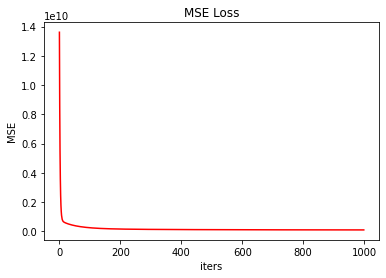

In [ ]:
plt.plot(mse_history, color='RED')
plt.title("MSE Loss")
plt.xlabel("iters")
plt.ylabel("MSE")
plt.show()